# Carter rank-1 strategy · bus 6141 · finalized 500 MW

**Executed strategy report derived from [main_template.ipynb](main_template.ipynb).**
Only the finalized **500 MW per team per submission** case is retained.

**Hypothesis:** Keep C = G and use Carter's rank-1 bus to isolate the siting benefit.

**Plan:** one new 500 MW C = G site at bus **6141** in each graded submission,
with no batteries. S1's hourly net grid withdrawal is fixed base load for S2;
the network resets before Week 3. All 120 periods were evaluated without other
teams. The notebook reads saved results and does not rerun the game.

The overview, plots, and calculated findings all describe this single capacity
case. Choose a profile week or scenario in **Inputs and selectors** and Run All.
See the [notebook guide](README.md) and [scoring definitions](../docs/SCORING.md).

## 01 · Imports and common presentation

The root is discovered from the working directory, so this notebook runs from
either the team root or `notebooks/`. No machine-specific paths are required.

In [1]:
from pathlib import Path
from datetime import datetime
from collections import defaultdict
import hashlib
import json
import os
import sys
import tempfile

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'src/team_strategy').is_dir() and (path / 'pyproject.toml').is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError('Open this notebook from the team repository or notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'ercot-team-mpl'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from team_strategy.experiments.interpretation import (
    ResultSource, ROUND_KEYS, COST_FIELDS,
    load_result_records, campaign_records, assert_comparable,
)
from team_strategy.experiments.scoring import ScoreBounds, combined_score_usd
from team_strategy.experiments.comparison import compare, frontier_names
from team_strategy.contracts import GRADED_ROUNDS

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (11, 5), 'figure.dpi': 110, 'savefig.dpi': 160,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.axisbelow': True, 'grid.alpha': 0.18,
})
pd.set_option('display.max_columns', 20)
ROUND_LABELS = dict(zip(ROUND_KEYS, ['W2 S1', 'W2 S2', 'W3 S1', 'W3 S2']))

## 02 · Inputs and selectors

Only the finalized **500 MW per-submission** case is retained. Add saved strategy
results to `SOURCES`, select a matched scenario, choose the focus strategy and
profile week, and Run All. The CSV and primary summary must agree. Export is
optional; this notebook does not run dispatch.

In [2]:
SOURCES = [
    ResultSource(
        strategy='carter_rank1_cg', label='Carter rank 1 · bus 6141',
        summary_json=ROOT / 'analysis/carter_rank1_cg_500mw.json',
        details_csv=ROOT / 'analysis/carter_rank1_cg_500mw.csv',
    ),
]

EXPERIMENT = 'finalized-500mw'  # Finalized 500 MW; only retained capacity case.
SCENARIO_ID = 'solo'
FOCUS_STRATEGY = 'carter_rank1_cg'
PROFILE_WEEK = 2                  # 2 or 3; optional hourly profiles.
RISK_CAMPAIGNS_FILE = None        # No multi-scenario evidence exists for this report yet.

EXPORT_FIGURES = False
EXPORT_DIR = ROOT / 'runs/interpretation/carter_rank1_cg' / datetime.now().strftime('%Y%m%d-%H%M%S-%f')

## 03 · Load, check, and summarize

The loader rejects duplicate rounds, CSV/JSON disagreements, nonfinite scores,
unreconciled cost breakdowns, and invalid energy shares. The comparison checks
the initial network, rules, release fingerprint, and capacity budget. An
incomplete campaign is shown as incomplete and receives **no normalized score**.
Missing scores and evaluator failures are not filled with zero.

In [3]:
records = load_result_records(SOURCES)
all_rounds = pd.DataFrame(records)
available = all_rounds[['experiment', 'capacity_per_submission_mw', 'scenario_id']].drop_duplicates()
# Saved finalized 500 MW campaign.
all_case_summary = pd.DataFrame(campaign_records(records))
display(Markdown('### Finalized 500 MW campaign'))
display(all_case_summary[['experiment', 'capacity_per_submission_mw', 'completed_rounds',
                          'score_billions', 'normalized_score', 'minimum_service_fraction']]
        .round({'score_billions': 3, 'normalized_score': 2, 'minimum_service_fraction': 4}))

experiment_rows = [row for row in records if row['experiment'] == EXPERIMENT]
assert_comparable(experiment_rows)
selected_records = [row for row in experiment_rows if row['scenario_id'] == SCENARIO_ID]
if not selected_records:
    raise ValueError(f'No rows match scenario {SCENARIO_ID!r}.')
experiment_strategies = {row['strategy'] for row in experiment_rows}
if {row['strategy'] for row in selected_records} != experiment_strategies:
    raise ValueError('The selected scenario is not available for every strategy.')

rounds = pd.DataFrame(selected_records)
rounds['round'] = pd.Categorical(rounds['round'], categories=ROUND_KEYS, ordered=True)
rounds = rounds.sort_values(['strategy', 'round']).reset_index(drop=True)
campaigns = pd.DataFrame(campaign_records(selected_records))
capacity_mw = float(rounds['capacity_per_submission_mw'].iloc[0])
bounds = ScoreBounds(capacity_mw)
strategy_ids = list(dict.fromkeys(source.strategy for source in SOURCES if source.strategy in experiment_strategies))
labels = {row['strategy']: row['label'] for row in selected_records}
palette = ['#27658A', '#D2793D', '#37816A', '#8A65A4', '#BF5363', '#87933E']
colors = {key: palette[index % len(palette)] for index, key in enumerate(strategy_ids)}
# Preserve the same strategy colors as the shared comparison template.
known_colors = {'full_generation': '#27658A', 'carter_rank1_cg': '#D2793D'}
colors.update({key: value for key, value in known_colors.items() if key in colors})
if FOCUS_STRATEGY not in strategy_ids:
    raise ValueError('FOCUS_STRATEGY must be present in the selected scenario.')
scope = 'FINALIZED PROJECT CAP'
subtitle = f'{scope} · {capacity_mw:g} MW per submission · scenario: {SCENARIO_ID}'
display(Markdown(f'**{subtitle}**'))
display(campaigns[['label', 'completed_rounds', 'complete', 'score_billions',
                   'normalized_score', 'minimum_service_fraction', 'all_valid', 'all_feasible']]
        .round({'score_billions': 3, 'normalized_score': 2, 'minimum_service_fraction': 4}))

if not campaigns['complete'].all():
    display(Markdown('**Incomplete campaign:** partial scores can be explored, but Q and final comparisons are withheld.'))
if not campaigns[['all_valid', 'all_feasible']].all().all():
    display(Markdown('**Inspect invalid/infeasible submissions before interpreting performance.**'))

### Finalized 500 MW campaign

,experiment,capacity_per_submission_mw,completed_rounds,score_billions,normalized_score,minimum_service_fraction
0,finalized-500mw,500.0,4,67.955,78.2,1.0


**FINALIZED PROJECT CAP · 500 MW per submission · scenario: solo**

,label,completed_rounds,complete,score_billions,normalized_score,minimum_service_fraction,all_valid,all_feasible
0,Carter rank 1 · bus 6141,4,True,67.955,78.2,1.0,True,True


In [4]:
# Common helpers. Exports are opt-in; normal execution only reads result files.
figures = {}

def present(fig, name):
    figures[name] = fig
    if EXPORT_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(EXPORT_DIR / f'{name}.png', bbox_inches='tight')
    display(fig)
    plt.close(fig)

def finish_axis(ax, ylabel=None):
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(axis='y')

def round_matrix(column):
    return rounds.pivot(index='round', columns='strategy', values=column).reindex(ROUND_KEYS)

def missing_panel(ax, message):
    ax.set_axis_off()
    ax.text(0.5, 0.5, message, ha='center', va='center', transform=ax.transAxes,
            fontsize=12, color='#687785', wrap=True)

## 04 · Where does each strategy earn its score?

Compare S1 and S2 separately, then view cumulative **score contributions**.
The cumulative line does not represent physical assets carried between weeks.
No missing round is silently replaced with zero.

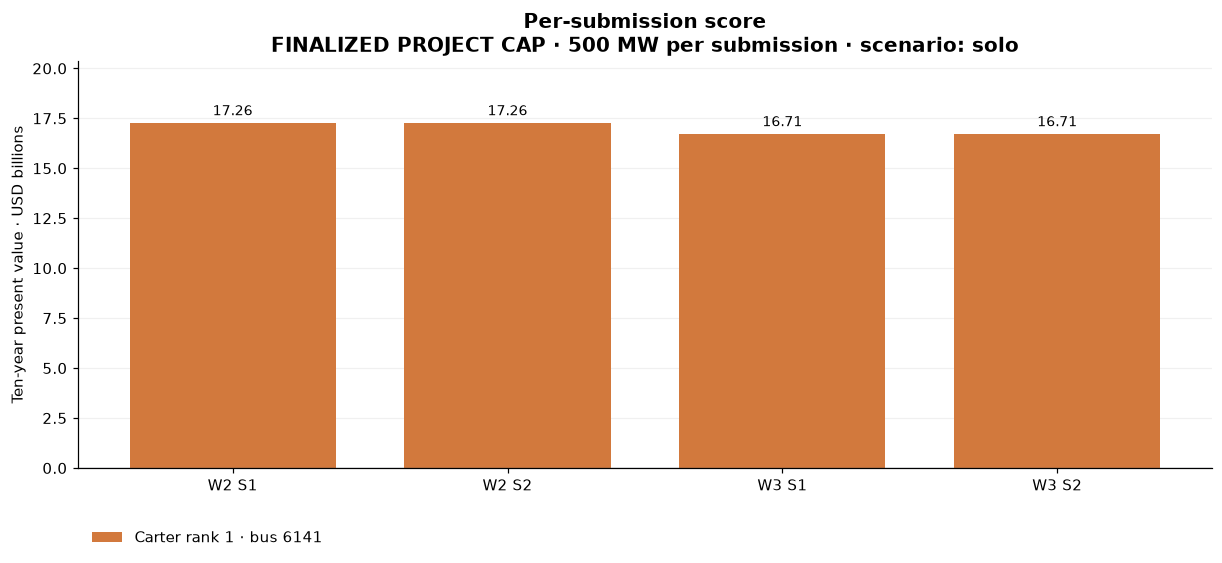

In [5]:
score_matrix = round_matrix('score_usd') / 1e9
x = np.arange(len(ROUND_KEYS))
width = 0.75 / len(strategy_ids)
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
for index, key in enumerate(strategy_ids):
    positions = x + (index - (len(strategy_ids) - 1) / 2) * width
    bars = ax.bar(positions, score_matrix[key], width, color=colors[key], label=labels[key])
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
ax.axhline(0, color='#697785', linewidth=0.8)
ax.set_xticks(x, [ROUND_LABELS[key] for key in ROUND_KEYS])
ax.set_title(f'Per-submission score\n{subtitle}')
finish_axis(ax, 'Ten-year present value · USD billions')
ax.margins(y=0.18)
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.12), ncol=min(3, len(strategy_ids)), frameon=False)
present(fig, '01_round_scores')

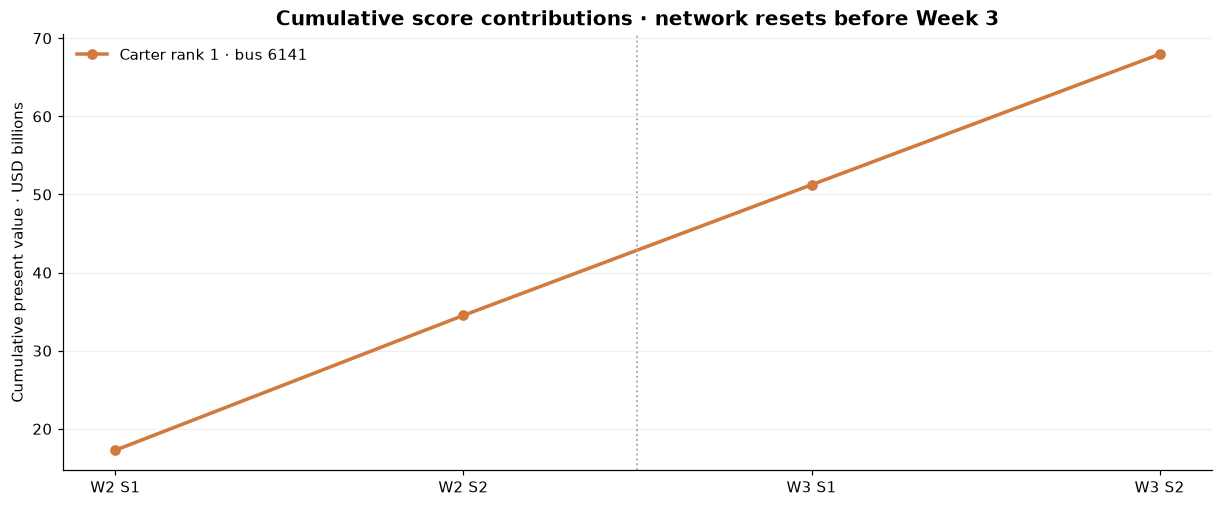

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
for key in strategy_ids:
    # skipna=False prevents a later point implying an incomplete campaign total.
    cumulative = score_matrix[key].cumsum(skipna=False)
    ax.plot(x, cumulative, marker='o', linewidth=2.3, color=colors[key], label=labels[key])
ax.axvline(1.5, color='#9DA8B1', linestyle=':', linewidth=1.2)
ax.set_xticks(x, [ROUND_LABELS[key] for key in ROUND_KEYS])
ax.set_title('Cumulative score contributions · network resets before Week 3')
finish_axis(ax, 'Cumulative present value · USD billions')
ax.legend(frameon=False)
present(fig, '02_cumulative_scores')

## 05 · Campaign score and normalized Q

Q uses the **four graded scores**, with budget-scaled anchors. Negative values and
values above 100 remain visible. The zero-price grid anchor is an idealized bound;
Week 3 actually uses joint-dispatch LMPs. The analytical C = G anchor and the
measured C = G strategy are different quantities.

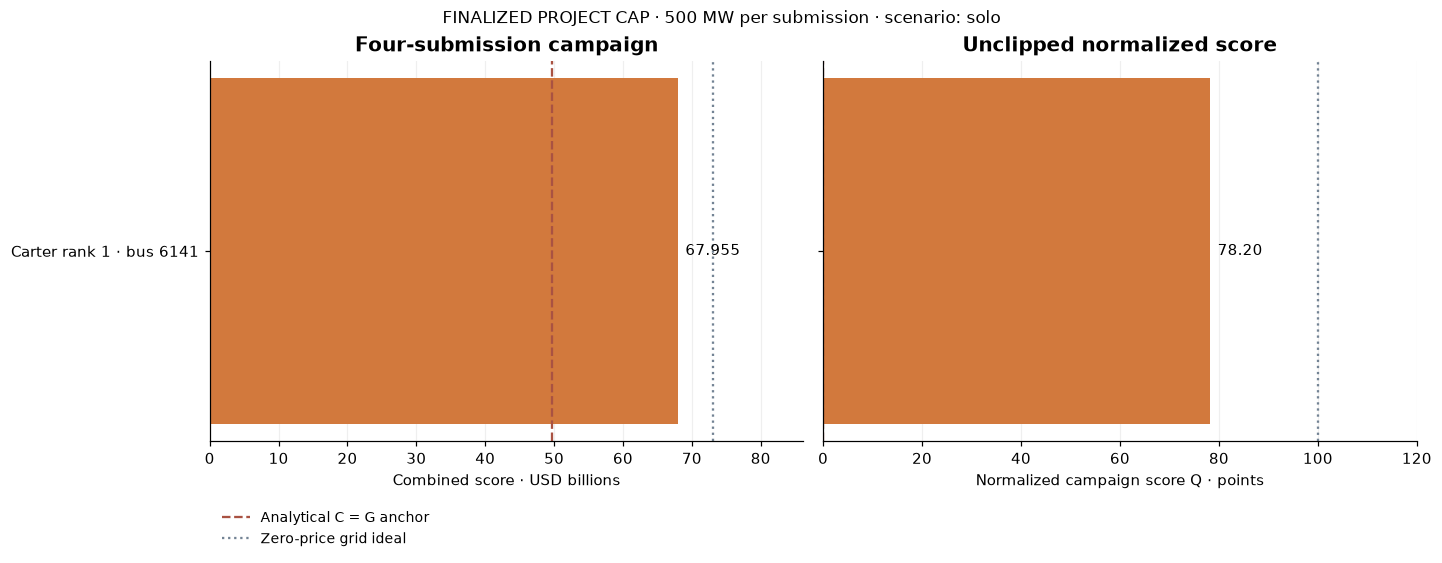

In [7]:
complete = campaigns[campaigns['complete']].set_index('strategy').reindex(strategy_ids).dropna(subset=['score_usd'])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
if complete.empty:
    for ax in axes:
        missing_panel(ax, 'Complete all four graded submissions to compare campaign scores and Q.')
else:
    y = np.arange(len(complete))
    bar_colors = [colors[key] for key in complete.index]
    bars = axes[0].barh(y, complete['score_billions'], color=bar_colors, height=0.55)
    axes[0].bar_label(bars, fmt='%.3f', padding=5)
    axes[0].axvline(bounds.lower_billions, color='#A95242', linestyle='--', label='Analytical C = G anchor')
    axes[0].axvline(bounds.upper_billions, color='#738394', linestyle=':', label='Zero-price grid ideal')
    axes[0].set_yticks(y, complete['label'])
    axes[0].set_xlabel('Combined score · USD billions')
    axes[0].set_title('Four-submission campaign')
    axes[0].margins(x=0.18)
    axes[0].legend(loc='upper left', bbox_to_anchor=(0, -0.15), frameon=False, fontsize=9)
    bars = axes[1].barh(y, complete['normalized_score'], color=bar_colors, height=0.55)
    axes[1].bar_label(bars, fmt='%.2f', padding=5)
    axes[1].axvline(0, color='#A95242', linestyle='--')
    axes[1].axvline(100, color='#738394', linestyle=':')
    axes[1].set_yticks(y, [])
    axes[1].set_xlabel('Normalized campaign score Q · points')
    axes[1].set_title('Unclipped normalized score')
    axes[1].margins(x=0.2)
    for ax in axes:
        ax.invert_yaxis()
        ax.grid(axis='x', alpha=0.2)
fig.suptitle(subtitle, fontsize=11)
present(fig, '03_campaign_score_and_q')

## 06 · Explain the economics

Positive stacked bars below are **costs**. Markers show gross IT value and net
score; net = IT value minus every cost component. Storage capital is read from
the summary JSON even when an older convenience CSV omits that column.

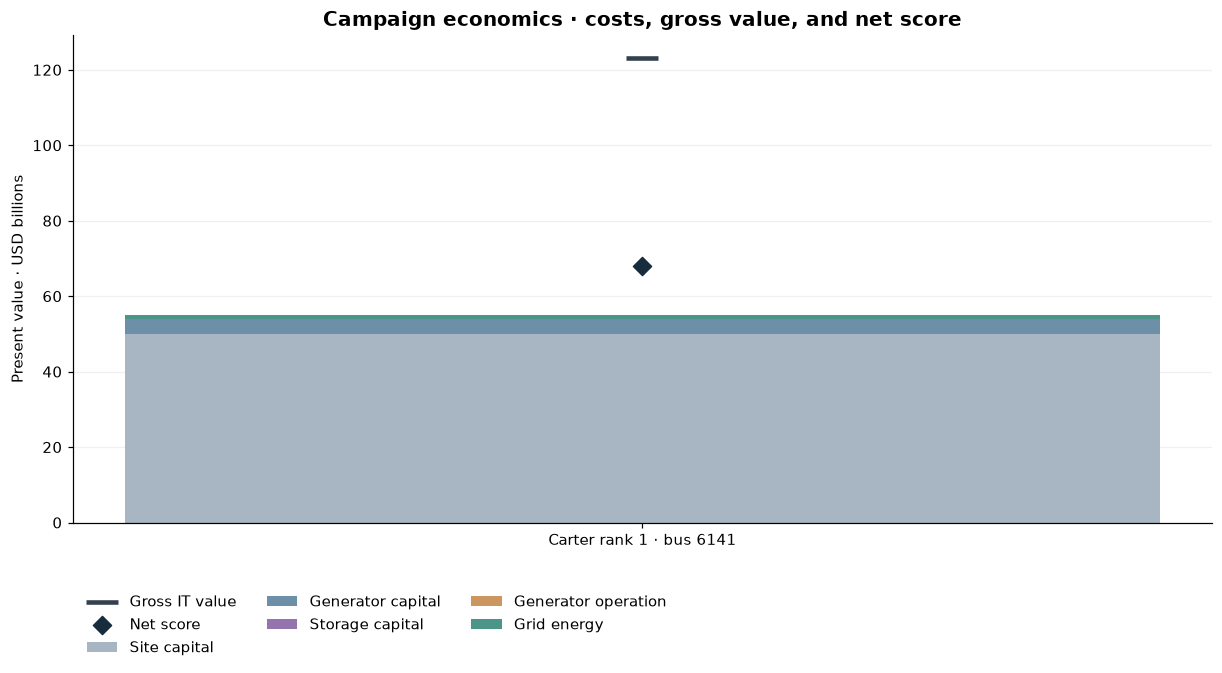

In [8]:
component_labels = {
    'site_cost_usd': 'Site capital',
    'generator_capital_cost_usd': 'Generator capital',
    'storage_capital_cost_usd': 'Storage capital',
    'generator_operating_cost_usd': 'Generator operation',
    'energy_cost_usd': 'Grid energy',
}
component_colors = ['#A7B6C2', '#6D8FA7', '#9474AC', '#CB965F', '#4C9689']
component_columns = list(component_labels)
totals = rounds.groupby('strategy')[['it_value_usd', 'score_usd', *component_columns]].sum().reindex(strategy_ids) / 1e9
fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')
bottom = np.zeros(len(strategy_ids))
for column, color in zip(component_columns, component_colors):
    values = totals[column].to_numpy()
    ax.bar(np.arange(len(strategy_ids)), values, bottom=bottom, color=color, width=0.55, label=component_labels[column])
    bottom += values
ax.scatter(np.arange(len(strategy_ids)), totals['it_value_usd'], marker='_', s=450,
           linewidths=3, color='#33414F', label='Gross IT value', zorder=5)
ax.scatter(np.arange(len(strategy_ids)), totals['score_usd'], marker='D', s=70,
           color='#172C3D', label='Net score', zorder=6)
ax.set_xticks(np.arange(len(strategy_ids)), [labels[key] for key in strategy_ids])
ax.set_title('Campaign economics · costs, gross value, and net score')
finish_axis(ax, 'Present value · USD billions')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.12), ncol=3, frameon=False)
present(fig, '04_cost_breakdown')

### Focus-strategy waterfall

Change `FOCUS_STRATEGY` to reuse this figure for another approach. For incomplete
campaigns this waterfall covers only the observed rounds, as labelled.

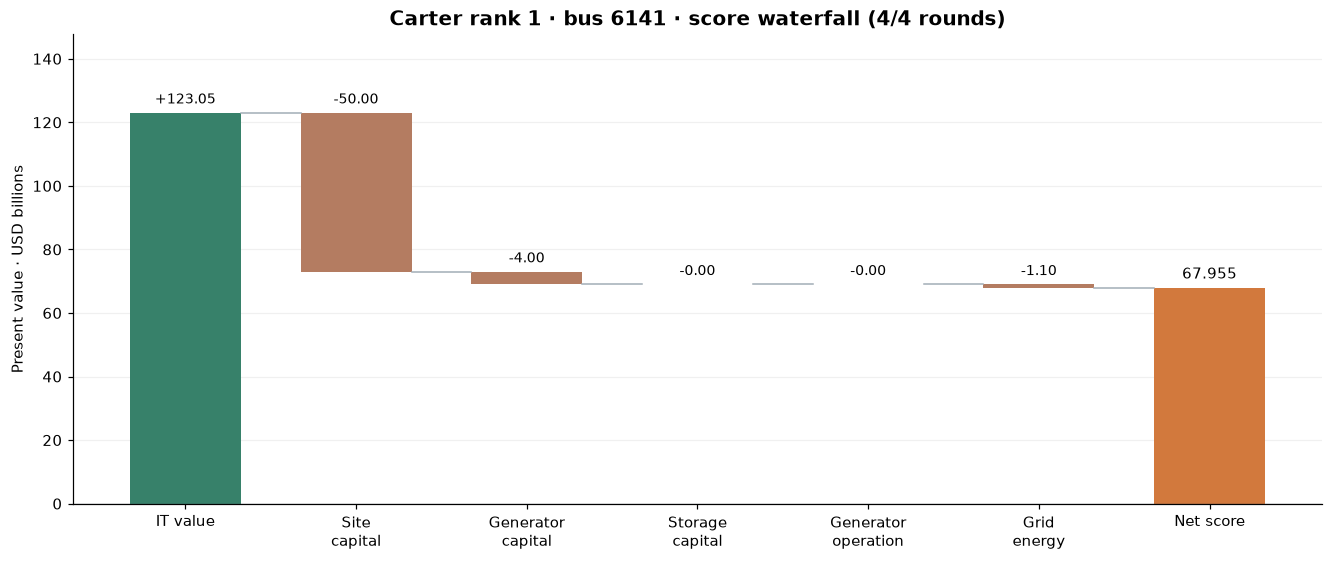

In [9]:
focus = totals.loc[FOCUS_STRATEGY]
steps = ['IT value', 'Site\ncapital', 'Generator\ncapital', 'Storage\ncapital', 'Generator\noperation', 'Grid\nenergy', 'Net score']
changes = [focus['it_value_usd'], *[-focus[column] for column in component_columns]]
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
running = 0.0
for index, change in enumerate(changes):
    after = running + change
    color = '#37816A' if change >= 0 else '#B47C61'
    ax.bar(index, abs(change), bottom=min(running, after), color=color, width=0.65)
    ax.annotate(f'{change:+.2f}', (index, max(running, after)), xytext=(0, 6),
                textcoords='offset points', ha='center', fontsize=9)
    ax.plot([index + 0.325, index + 0.675], [after, after], color='#A2ADB6', linewidth=1)
    running = after
ax.bar(6, abs(running), bottom=min(0, running), color=colors[FOCUS_STRATEGY], width=0.65)
ax.annotate(f'{running:.3f}', (6, max(0, running)), xytext=(0, 6), textcoords='offset points', ha='center')
ax.set_xticks(range(7), steps)
round_count = int(campaigns.set_index('strategy').loc[FOCUS_STRATEGY, 'completed_rounds'])
ax.set_title(f'{labels[FOCUS_STRATEGY]} · score waterfall ({round_count}/4 rounds)')
ax.axhline(0, color='#657582', linewidth=0.8)
finish_axis(ax, 'Present value · USD billions')
ax.margins(y=0.2)
present(fig, '05_focus_waterfall')

## 07 · Was requested connection capacity allocated?

This is the team service fraction: **allocated / requested connection capacity**,
not the grid share of electricity. A team can receive 100% allocation and use
mostly private generation. With multiple sites, a team fraction does not imply
identical individual-site fractions. Missing rounds are grey, not zero.

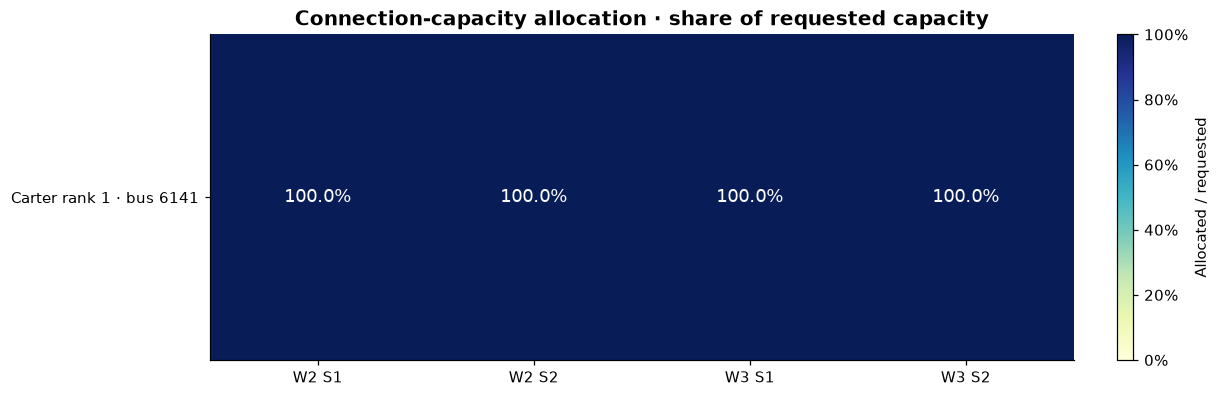

In [10]:
allocation = round_matrix('service_fraction').reindex(columns=strategy_ids).T
fig, ax = plt.subplots(figsize=(11, max(3.5, 0.7 * len(strategy_ids) + 1.8)), layout='constrained')
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_bad('#ECEFF2')
image = ax.imshow(np.ma.masked_invalid(allocation.to_numpy(dtype=float)), cmap=cmap, vmin=0, vmax=1, aspect='auto')
for i in range(len(strategy_ids)):
    for j in range(4):
        value = allocation.iloc[i, j]
        state = rounds[(rounds['strategy'] == strategy_ids[i]) & (rounds['round'] == ROUND_KEYS[j])]
        caption = f'{value:.1%}' if pd.notna(value) else ('missing' if state.empty else 'unreported')
        if not state.empty and not bool(state.iloc[0]['valid']):
            caption = 'invalid'
        ax.text(j, i, caption, ha='center', va='center',
                color='white' if pd.notna(value) and value > 0.65 else '#233341', fontsize=12)
ax.set_xticks(range(4), [ROUND_LABELS[key] for key in ROUND_KEYS])
ax.set_yticks(range(len(strategy_ids)), [labels[key] for key in strategy_ids])
ax.set_title('Connection-capacity allocation · share of requested capacity')
fig.colorbar(image, ax=ax, format=PercentFormatter(1), label='Allocated / requested')
present(fig, '06_allocation')

## 08 · Where did electricity come from?

Shares are **weighted energy**, not installed capacity or a constant hourly
dispatch fraction. Grid and private generation are primary sources. Batteries
shift energy through time and must not be added as a third source, which would
double-count the energy used to charge them. This chart is conditional on both
energy-share columns being available in the details CSV.

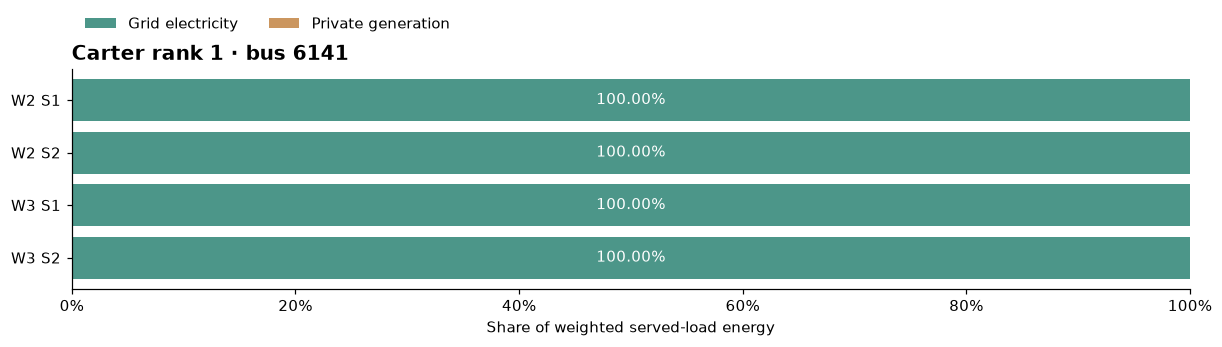

In [11]:
fig, axes = plt.subplots(len(strategy_ids), 1, figsize=(11, 3 * len(strategy_ids)),
                         layout='constrained', squeeze=False)
for ax, key in zip(axes[:, 0], strategy_ids):
    block = rounds[rounds['strategy'] == key].set_index('round').reindex(ROUND_KEYS)
    shares = ['grid_supply_share', 'private_generation_share']
    if not all(column in block.columns for column in shares) or block[shares].isna().any().any():
        missing_panel(ax, f'{labels[key]}: weighted energy shares are unavailable for one or more rounds.')
        continue
    grid = block['grid_supply_share'].to_numpy() * 100
    private = block['private_generation_share'].to_numpy() * 100
    ax.barh(x, grid, color='#4C9689', label='Grid electricity')
    ax.barh(x, private, left=grid, color='#CB965F', label='Private generation')
    for index, (g, p) in enumerate(zip(grid, private)):
        if g >= 7:
            ax.text(g / 2, index, f'{g:.2f}%', ha='center', va='center', color='white')
        if p >= 7:
            ax.text(g + p / 2, index, f'{p:.2f}%', ha='center', va='center', color='#263542')
    ax.set_yticks(x, [ROUND_LABELS[round] for round in ROUND_KEYS])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.set_title(labels[key], loc='left')
    ax.set_xlabel('Share of weighted served-load energy')
axes[0, 0].legend(loc='upper left', bbox_to_anchor=(0, 1.3), ncol=2, frameon=False)
present(fig, '07_energy_supply')

## 09 · Optional site choices and hourly grid withdrawal

These panels use the original run folders, which are ignored by Git. They are
optional: teammates can interpret campaign scores using only the committed
`analysis/` files. Missing raw files produce an explanation, not invented data.
S2 profiles describe **new S2 sites**, with S1 already frozen into the base load.

,strategy,round,site_id,bus_id,connection_capacity_mw,generator_capacity_mw,storage_power_mw,storage_energy_mwh
0,Carter rank 1 · bus 6141,W2 S1,w2-s1-0001,6141,500.0,500.0,0.0,0.0
1,Carter rank 1 · bus 6141,W2 S2,w2-s2-0001,6141,500.0,500.0,0.0,0.0
2,Carter rank 1 · bus 6141,W3 S1,w3-s1-0001,6141,500.0,500.0,0.0,0.0
3,Carter rank 1 · bus 6141,W3 S2,w3-s2-0001,6141,500.0,500.0,0.0,0.0


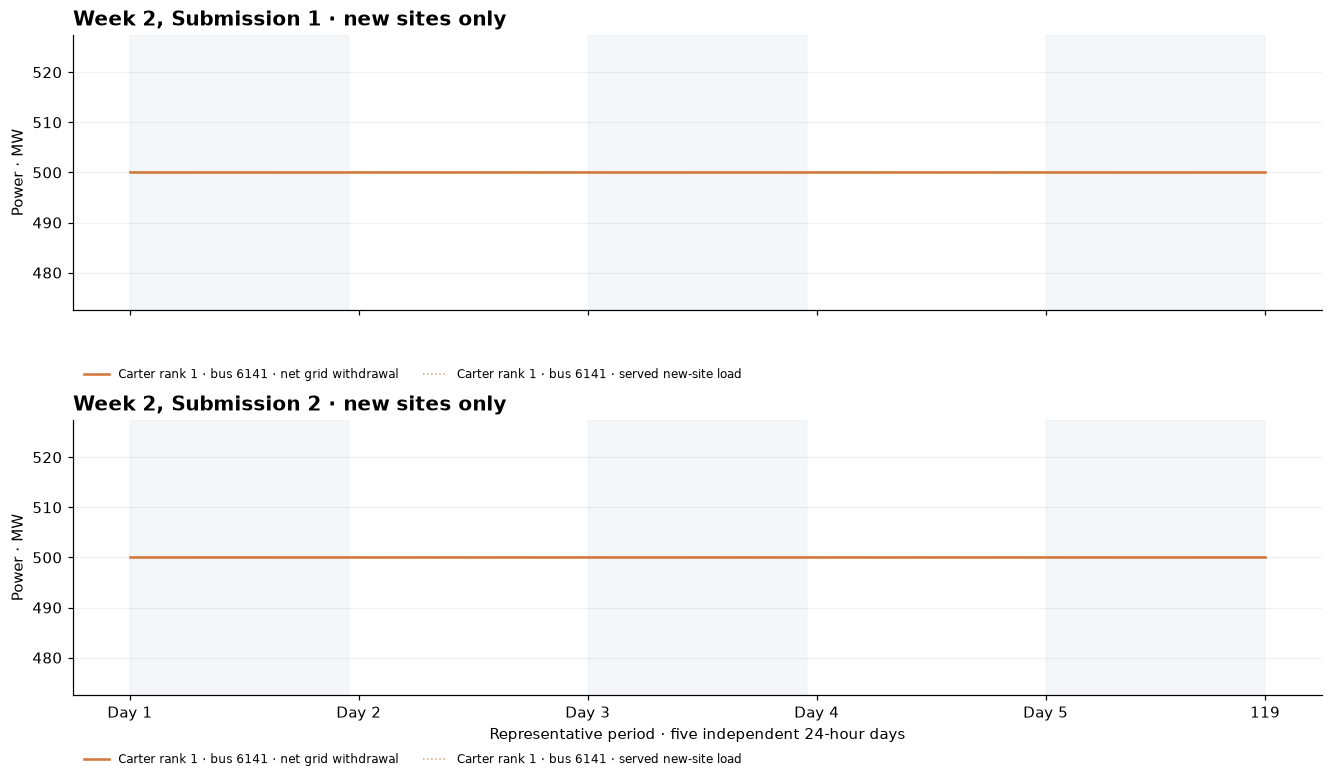

In [12]:
site_tables = []
profiles = {}
for row in selected_records:
    if not row.get('raw_run_directory'):
        continue
    directory = ROOT / row['raw_run_directory'] / row['experiment'] / row['round']
    candidate = directory / 'candidate/candidate.csv'
    if candidate.is_file():
        sites = pd.read_csv(candidate, dtype={'bus_id': str})
        sites.insert(0, 'strategy', row['label'])
        sites.insert(1, 'round', ROUND_LABELS[row['round']])
        site_tables.append(sites)
    withdrawal = directory / 'results/site_net_withdrawal.csv'
    if row['round'].startswith(f'week-{PROFILE_WEEK}-') and withdrawal.is_file():
        frame = pd.read_csv(withdrawal)
        profiles[(row['strategy'], row['round'])] = frame.groupby('period_index')[['net_withdrawal_mw', 'load_mw']].sum()
if site_tables:
    display(pd.concat(site_tables, ignore_index=True)[[
        'strategy', 'round', 'site_id', 'bus_id', 'connection_capacity_mw',
        'generator_capacity_mw', 'storage_power_mw', 'storage_energy_mwh',
    ]])
else:
    display(Markdown('Raw candidate files are unavailable. Site tables are skipped.'))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout='constrained', sharex=True)
for submission, ax in enumerate(axes, start=1):
    found = False
    for key in strategy_ids:
        data = profiles.get((key, f'week-{PROFILE_WEEK}-submission-{submission}'))
        if data is None:
            continue
        found = True
        ax.plot(data.index, data['net_withdrawal_mw'], color=colors[key], linewidth=1.7,
                label=f'{labels[key]} · net grid withdrawal')
        ax.plot(data.index, data['load_mw'], color=colors[key], linestyle=':', linewidth=1,
                alpha=0.7, label=f'{labels[key]} · served new-site load')
    if not found:
        missing_panel(ax, 'Raw hourly withdrawal exports are unavailable for this submission.')
        continue
    for day in range(5):
        if day % 2 == 0:
            ax.axvspan(day * 24, day * 24 + 23, color='#E8EEF2', alpha=0.45, zorder=0)
    ax.set_title(f'Week {PROFILE_WEEK}, Submission {submission} · new sites only', loc='left')
    finish_axis(ax, 'Power · MW')
    ax.legend(fontsize=8, ncol=2, frameon=False, loc='upper left', bbox_to_anchor=(0, -0.17))
axes[-1].set_xticks([0, 24, 48, 72, 96, 119], ['Day 1', 'Day 2', 'Day 3', 'Day 4', 'Day 5', '119'])
axes[-1].set_xlabel('Representative period · five independent 24-hour days')
present(fig, '08_hourly_grid_withdrawal')

## 10 · Average normalized score versus downside risk

The retained experiment is **500 MW per submission**. This panel needs at least
two matched complete opponent campaign scenarios per strategy. A single solo
run does not establish downside risk, and no zero-risk point is invented.

Use all loaded scenarios in the finalized experiment, or supply a real CLI-format
campaign input through `RISK_CAMPAIGNS_FILE`. Capacity, economics, and opponent
assumptions must match. The shared lower-semideviation and Pareto definitions
apply; there is no weighted composite score.

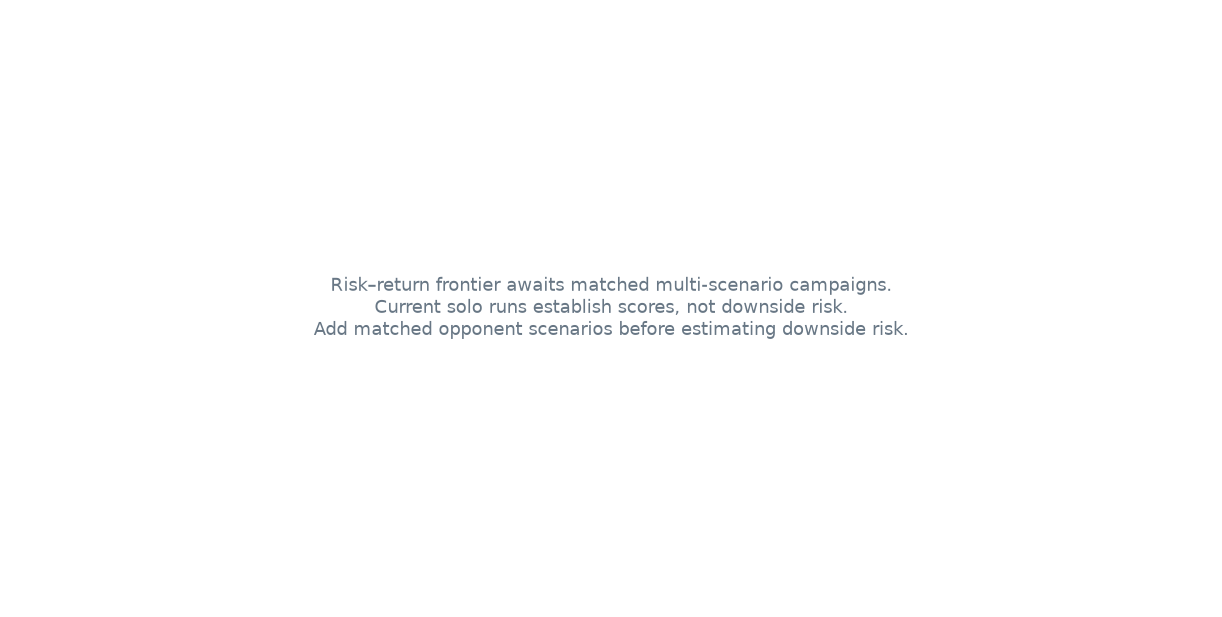

In [13]:
all_campaigns = campaign_records(experiment_rows)
risk_totals = defaultdict(dict, {key: {} for key in strategy_ids})
if RISK_CAMPAIGNS_FILE is None:
    for row in all_campaigns:
        if row['complete']:
            risk_totals[row['strategy']][row['scenario_id']] = row['score_usd']
else:
    risk_path = Path(RISK_CAMPAIGNS_FILE)
    if not risk_path.is_absolute():
        risk_path = ROOT / risk_path
    risk_input = json.loads(risk_path.read_text())
    if float(risk_input['capacity_per_submission_mw']) != capacity_mw:
        raise ValueError('Risk input budget differs from the selected experiment.')
    round_lookup = {round.key: round for round in GRADED_ROUNDS}
    for strategy, scenarios in risk_input['strategies'].items():
        for scenario, scores in scenarios.items():
            if set(scores) != set(round_lookup):
                raise ValueError('Each risk observation requires exactly four graded scores.')
            risk_totals[strategy][scenario] = combined_score_usd({round_lookup[key]: value for key, value in scores.items()})

fig, ax = plt.subplots(figsize=(11, 5.5), layout='constrained')
if not risk_totals or any(len(values) < 2 for values in risk_totals.values()):
    risk_summary = None
    missing_panel(ax, 'Risk–return frontier awaits matched multi-scenario campaigns.\nCurrent solo runs establish scores, not downside risk.\nAdd matched opponent scenarios before estimating downside risk.')
else:
    risk_summary = compare(dict(risk_totals), bounds)
    frontier = frontier_names(risk_summary)
    for index, item in enumerate(risk_summary):
        ax.scatter(item.downside_risk, item.average_normalized_score,
                   marker='D' if item.name in frontier else 'o', s=80,
                   color=colors.get(item.name, palette[index % len(palette)]))
        ax.annotate(labels.get(item.name, item.name),
                    (item.downside_risk, item.average_normalized_score),
                    xytext=(6, 6), textcoords='offset points', fontsize=9)
    ax.axhline(0, color='#A95242', linestyle='--', label='Analytical C = G anchor')
    ax.axhline(100, color='#738394', linestyle=':', label='Zero-price grid ideal')
    ax.set(xlabel='Downside risk · lower semideviation in normalized points',
           ylabel='Average normalized campaign score Q', title='Risk–return frontier · diamonds are nondominated')
    ax.grid(alpha=0.2)
    ax.margins(x=0.25, y=0.2)
    ax.legend(frameon=False)
    display(pd.DataFrame([vars(item) for item in risk_summary]))
present(fig, '09_risk_return_frontier')

## 11 · Findings from this strategy's saved results

The interpretation below is computed from the selected capacity case, so it
updates when `EXPERIMENT` changes. Capacity allocation, energy source, and
installed generator capacity are kept separate. The reference comparison uses
the saved baseline-versus-Carter comparison at the same budget.


In [14]:
selected_campaign = campaigns.set_index('strategy').loc[FOCUS_STRATEGY]
selected_rounds = rounds[rounds['strategy'] == FOCUS_STRATEGY].set_index('round').reindex(ROUND_KEYS)
selected_components = totals.loc[FOCUS_STRATEGY]
observed_grid = selected_rounds['grid_supply_share'] * 100
observed_private = selected_rounds['private_generation_share'] * 100
supply_summary = pd.DataFrame({
    'submission': [ROUND_LABELS[key] for key in ROUND_KEYS],
    'grid_energy_percent': observed_grid.to_numpy(),
    'private_generation_percent': observed_private.to_numpy(),
    'score_billions': selected_rounds['score_usd'].to_numpy() / 1e9,
})
comparison = pd.read_csv(ROOT / 'analysis/cg_bus_comparison_500mw.csv')
reference = comparison[comparison['experiment'] == EXPERIMENT].iloc[0]
if not np.isclose(selected_campaign['score_billions'], reference['carter_combined_score_billions'], rtol=1e-12):
    raise ValueError('The saved comparison is stale relative to this campaign summary.')
display(Markdown(
    f"**Selected case:** {subtitle}.\n\n"
    f"- **Combined score:** ${selected_campaign['score_billions']:.3f}B; "
    f"**Q = {selected_campaign['normalized_score']:.2f}**.\n"
    f"- **Allocation:** {selected_campaign['minimum_service_fraction']:.0%} in every graded submission; "
    "all four files were valid and feasible.\n"
    f"- **Private generation:** ${selected_components['generator_operating_cost_usd']:.3f}B in operating cost, "
    f"plus ${selected_components['generator_capital_cost_usd']:.3f}B in generator capital.\n"
    f"- **Grid settlement:** ${selected_components['energy_cost_usd']:.3f}B, charged in Week 3 only.\n"
    "- **Risk:** one solo campaign scenario at this budget; downside risk is not estimated."
))
display(supply_summary.round({'grid_energy_percent': 4, 'private_generation_percent': 4, 'score_billions': 3}))

if (observed_private.abs() < 1e-8).all():
    supply_finding = (
        "The grid supplied all electricity in every submission. The private generators were idle, "
        "but their capital cost was still paid. C = G here provided backup capacity rather than measured energy."
    )
else:
    supply_finding = (
        "The grid supplied all S1 electricity and almost all new-site S2 electricity. "
        "Private generation filled the small residual shown in the supply table. "
        "This greatly reduced generator operating costs compared with the default-bus baseline."
    )
display(Markdown(
    f"**Interpretation:** {supply_finding}\n\n"
    f"**Matched baseline:** Bus 1001 earned ${reference['baseline_combined_score_billions']:.3f}B. "
    f"Moving to bus 6141 improved the combined score by **${reference['improvement_billions']:.3f}B "
    f"({reference['improvement_percent']:.2f}%)** while keeping C = G, battery size, and requested capacity fixed. "
    "The ranking was used as a siting hypothesis; this solo result does not establish resilience to competitors."
))

**Selected case:** FINALIZED PROJECT CAP · 500 MW per submission · scenario: solo.

- **Combined score:** $67.955B; **Q = 78.20**.
- **Allocation:** 100% in every graded submission; all four files were valid and feasible.
- **Private generation:** $0.000B in operating cost, plus $4.000B in generator capital.
- **Grid settlement:** $1.098B, charged in Week 3 only.
- **Risk:** one solo campaign scenario at this budget; downside risk is not estimated.

,submission,grid_energy_percent,private_generation_percent,score_billions
0,W2 S1,100.0,0.0,17.263
1,W2 S2,100.0,0.0,17.263
2,W3 S1,100.0,0.0,16.715
3,W3 S2,100.0,0.0,16.714


**Interpretation:** The grid supplied all electricity in every submission. The private generators were idle, but their capital cost was still paid. C = G here provided backup capacity rather than measured energy.

**Matched baseline:** Bus 1001 earned $55.271B. Moving to bus 6141 improved the combined score by **$12.684B (22.95%)** while keeping C = G, battery size, and requested capacity fixed. The ranking was used as a siting hypothesis; this solo result does not establish resilience to competitors.

### Open questions for the team

- Does the result hold when other teams crowd the same buses?
- Which S1/S2 decisions should change after aggregate classroom feedback arrives?
- What additional evidence is needed before choosing a submission?

These are interpretation notes, not instructions to implement another strategy.


In [15]:
if EXPORT_FIGURES:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    rounds.to_csv(EXPORT_DIR / 'round_summary.csv', index=False)
    campaigns.to_csv(EXPORT_DIR / 'campaign_summary.csv', index=False)
    provenance = {
        'experiment': EXPERIMENT, 'scenario_id': SCENARIO_ID,
        'capacity_per_submission_mw': capacity_mw, 'focus_strategy': FOCUS_STRATEGY,
        'sources': [{
            'strategy': source.strategy, 'label': source.label,
            'summary': str(source.summary_json.relative_to(ROOT)),
            'summary_sha256': hashlib.sha256(source.summary_json.read_bytes()).hexdigest(),
            'details': str(source.details_csv.relative_to(ROOT)) if source.details_csv else None,
            'details_sha256': hashlib.sha256(source.details_csv.read_bytes()).hexdigest() if source.details_csv else None,
        } for source in SOURCES],
        'bounds_billions': {'lower': bounds.lower_billions, 'upper': bounds.upper_billions},
        'figures': list(figures),
    }
    (EXPORT_DIR / 'interpretation_manifest.json').write_text(json.dumps(provenance, indent=2) + '\n')
    display(Markdown(f'Exported **{len(figures)} figures**, tables, and input fingerprints to `{EXPORT_DIR.relative_to(ROOT)}`.'))
else:
    display(Markdown(f'**{len(figures)} reusable figures rendered.** Export is off; source results are unchanged.'))

**9 reusable figures rendered.** Export is off; source results are unchanged.